# FarmTech Solutions — Modelagem de IA

**Aluno:** Caio Barros Queiroz  
**RM:** 576443  
**Fase:** 3  
**Capítulo:** 11

> Rascunho em desenvolvimento. Notebook em desenvolvimento. Análises descritivas e cinco visualizações foram organizadas com dados reais; interpretações e treinamento de classificadores continuam pendentes de revisão do aluno.

## 1. Objetivo e contexto

Descrever o problema de classificação e o objetivo da recomendação de culturas. Explicar o significado da variável-alvo `label`.

## 2. Fonte e limitações dos dados

O arquivo foi fornecido pelo aluno como material da professora. A origem primária e a autorização de publicação ainda devem ser verificadas. Não assumir representatividade da agricultura brasileira.

## 3. Bibliotecas e configuração

Importar bibliotecas, conferir ambiente e definir a semente aleatória para experimentos reprodutíveis.

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

SEMENTE = 42  # Facilita a reproducibilidade dos experimentos futuros.


## 4. Carregamento e validação dos dados

Carregar o CSV local, verificar dimensões, tipos, ausentes, duplicatas, classes e valores numéricos não finitos. Esta verificação não demonstra representatividade agronômica.

In [2]:
# Leitura local: arquivos CSV nao sao enviados automaticamente para o GitHub.
# Coloque o CSV na pasta dados/ na raiz do projeto.
pastas_dados = [Path("dados"), Path("../dados")]
nomes_aceitos = ("Atividade_Cap11_produtos_agricolas*.csv", "produtos_agricolas.csv")
arquivos = sorted({
    caminho.resolve()
    for pasta in pastas_dados
    for nome in nomes_aceitos
    for caminho in pasta.glob(nome)
    if caminho.is_file()
})

if not arquivos:
    raise FileNotFoundError(
        "CSV ausente: salve Atividade_Cap11_produtos_agricolas(2).csv "
        "na pasta dados/ do projeto."
    )
if len(arquivos) > 1:
    raise ValueError(
        f"Mais de um CSV foi encontrado em dados/. Mantenha apenas um: {arquivos}"
    )

caminho_csv = arquivos[0]
dados = pd.read_csv(caminho_csv)
colunas_esperadas = {"N", "P", "K", "temperature", "humidity", "ph", "rainfall", "label"}
colunas_numericas = sorted(colunas_esperadas - {"label"})
faltantes = colunas_esperadas - set(dados.columns)
if faltantes:
    raise ValueError(f"Colunas obrigatorias ausentes: {sorted(faltantes)}")

for coluna in colunas_numericas:
    dados[coluna] = pd.to_numeric(dados[coluna], errors="raise")

print("Arquivo:", caminho_csv.name)
print("Linhas x colunas:", dados.shape)
print("Tipos dos dados:")
print(dados.dtypes)
print("Ausentes por coluna:")
print(dados.isna().sum())
print("Duplicatas integrais:", int(dados.duplicated().sum()))
print("Classes encontradas:", dados["label"].nunique())
print("Distribuicao por cultura:")
print(dados["label"].value_counts().sort_index())
print("Valores numericos nao finitos:",
      int((~np.isfinite(dados[colunas_numericas])).to_numpy().sum()))
display(dados.head())


Arquivo: Atividade_Cap11_produtos_agricolas(2).csv
Linhas x colunas: (2200, 8)
Tipos dos dados:
N                int64
P                int64
K                int64
temperature    float64
humidity       float64
ph             float64
rainfall       float64
label           object
dtype: object
Ausentes por coluna:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64
Duplicatas integrais: 0
Classes encontradas: 22
Distribuicao por cultura:
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64
Valores nume

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


## 5. Análise exploratória e descritiva

**Atividade do aluno:** calcular estatísticas descritivas, construir cinco gráficos diferentes e registrar uma interpretação para cada visualização, após revisar os dados carregados.

In [3]:
# Estatísticas descritivas das sete variáveis numéricas
display(dados.describe().round(2))

,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56


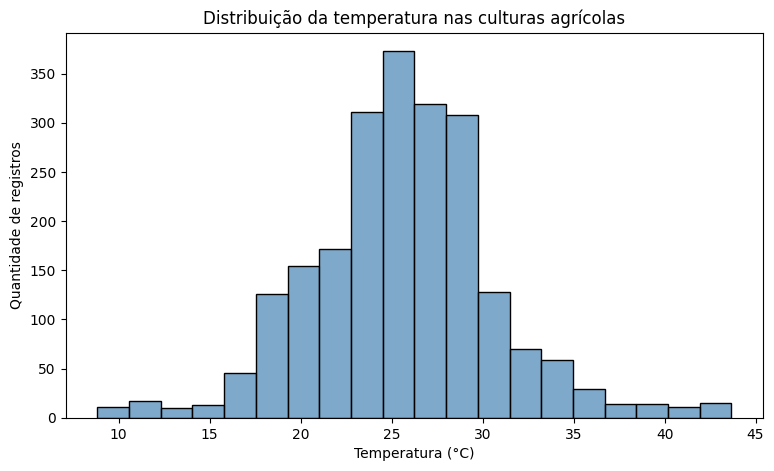

In [4]:
# Gráfico 1 — Distribuição da temperatura

plt.figure(figsize=(9, 5))

sns.histplot(
    data=dados,
    x="temperature",
    bins=20,
    color="#548db9"
)

plt.title("Distribuição da temperatura nas culturas agrícolas")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Quantidade de registros")

plt.show()

### Interpretação do Gráfico 1 — Histograma da temperatura

**PENDENTE — redigir com suas palavras:** indique a concentração aproximada das temperaturas (23–30 °C), a média observada (25,62 °C) e o limite de interpretar 22 culturas juntas.


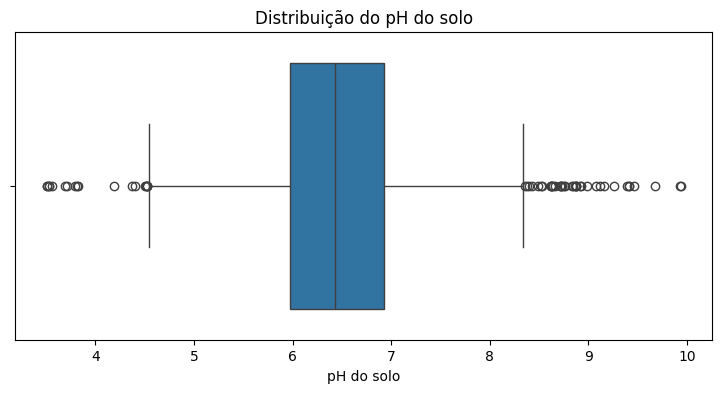

In [5]:
# Gráfico 2 — Distribuição do pH

plt.figure(figsize=(9, 4))

sns.boxplot(data=dados, x="ph")

plt.title("Distribuição do pH do solo")
plt.xlabel("pH do solo")

plt.show()

### Interpretação do Gráfico 2 — Distribuição do pH

**PENDENTE — redigir com suas palavras:** descreva a mediana (6,43), o intervalo interquartil (aproximadamente 5,97–6,92), os pontos atípicos e a limitação de agrupar diferentes culturas. Um valor atípico não é automaticamente um erro.


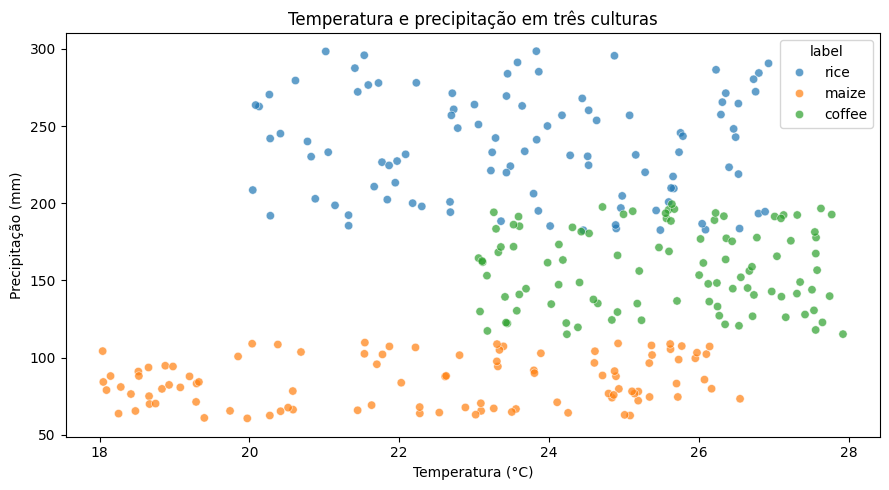

In [6]:
# Gráfico 3 — Relação entre temperatura e precipitação em três culturas
culturas = ["rice", "coffee", "maize"]
dados_filtrados = dados[dados["label"].isin(culturas)]

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=dados_filtrados,
    x="temperature",
    y="rainfall",
    hue="label",
    alpha=0.7,
)
plt.title("Temperatura e precipitação em três culturas")
plt.xlabel("Temperatura (°C)")
plt.ylabel("Precipitação (mm)")
plt.tight_layout()
plt.show()

### Interpretação do Gráfico 3 — Temperatura × precipitação

**PENDENTE — redigir com suas palavras:** compare as faixas de chuva e temperatura de arroz, milho e café, note sobreposições e explique por que o gráfico não prova causalidade ou exigências ideais das culturas.


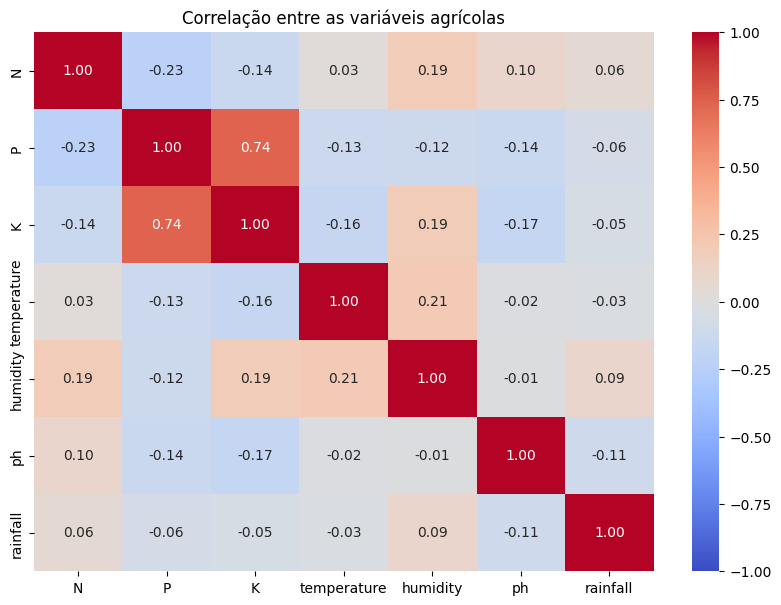

In [7]:

# Gráfico 4 — Mapa de calor de correlação

variaveis = [
    "N", "P", "K",
    "temperature", "humidity",
    "ph", "rainfall"
]

correlacao = dados[variaveis].corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlacao,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Correlação entre as variáveis agrícolas")

plt.show()


### Interpretação do Gráfico 4 — Mapa de calor

**PENDENTE — redigir com suas palavras:** a correlação entre P e K é aproximadamente +0,74, e entre N e P cerca de -0,23. Explique por que correlação não prova causalidade e por que correlações globais podem ocultar padrões específicos.


,N,P,K
label,,,
coffee,101.20,28.74,29.94
maize,77.76,48.44,19.79
rice,79.89,47.58,39.87


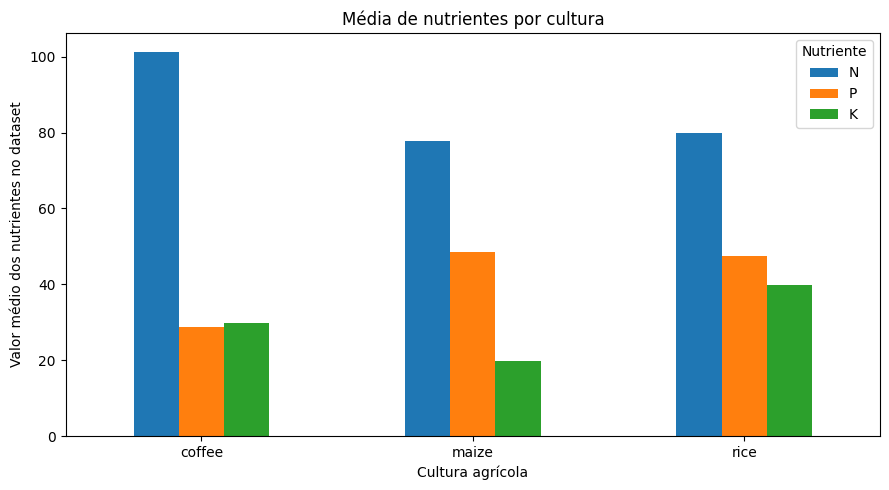

In [8]:

# Gráfico 5 — Comparação de nutrientes por cultura

culturas = ["rice", "coffee", "maize"]

dados_filtrados = dados[
    dados["label"].isin(culturas)
]

medias_nutrientes = dados_filtrados.groupby("label")[
    ["N", "P", "K"]
].mean()

display(medias_nutrientes.round(2))

medias_nutrientes.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Média de nutrientes por cultura")
plt.xlabel("Cultura agrícola")
plt.ylabel("Valor médio dos nutrientes no dataset")
plt.xticks(rotation=0)
plt.legend(title="Nutriente")
plt.tight_layout()

plt.show()


### Interpretação do Gráfico 5 — Nutrientes por cultura

**PENDENTE — redigir com suas palavras:** compare N, P e K para café, milho e arroz e explique por que médias observadas não são doses de fertilizante recomendadas.


## 6. Comparação de três culturas

Definir três culturas com justificativa e comparar nutrientes, temperatura, umidade, pH e precipitação. Não apresentar médias amostrais como limites agronômicos universais.

In [9]:
# Comparação descritiva: solo e clima para três culturas
# Os valores representam médias/desvios observados, não condições ideais de cultivo.
variaveis_comparacao = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
comparacao = dados[dados["label"].isin(["rice", "maize", "coffee"])]
display(comparacao.groupby("label")[variaveis_comparacao].mean().round(2))
display(comparacao.groupby("label")[variaveis_comparacao].std().round(2))

,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
coffee,101.20,28.74,29.94,25.54,58.87,6.79,158.07
maize,77.76,48.44,19.79,22.39,65.09,6.25,84.77
rice,79.89,47.58,39.87,23.69,82.27,6.43,236.18


,N,P,K,temperature,humidity,ph,rainfall
label,,,,,,,
coffee,12.35,7.28,3.25,1.50,5.84,0.42,25.70
maize,11.95,8.01,2.94,2.68,5.45,0.41,15.55
rice,11.92,7.90,2.95,2.03,1.42,0.77,34.29


## 7. Preparação para Machine Learning

Separar X e y, criar uma divisão treino/teste com estratificação e aplicar transformações somente sobre o treinamento, preferencialmente em pipelines.

In [10]:
# Preparação reprodutível: 80% treino, 20% teste
# A variável-alvo não pode aparecer entre as entradas.
from sklearn.model_selection import train_test_split

atributos = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
X = dados[atributos]
y = dados["label"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEMENTE,
    stratify=y,
)
print("Treino:", X_treino.shape, "Teste:", X_teste.shape)
print("Exemplos por classe no treino:", sorted(y_treino.value_counts().unique()))
print("Exemplos por classe no teste:", sorted(y_teste.value_counts().unique()))

Treino: (1760, 7) Teste: (440, 7)
Exemplos por classe no treino: [np.int64(80)]
Exemplos por classe no teste: [np.int64(20)]


**Exercício do aluno:** por que usar `stratify=y`? Por que um `StandardScaler` deve ser ajustado nos dados de treino e não no conjunto completo? Justifique antes de treinar os classificadores.


## 8. Treinamento dos cinco modelos

Treinar cinco classificadores de algoritmos diferentes e justificar a escolha. Comparar os modelos sob a mesma divisão e evitar vazamento de dados.

In [ ]:
# TODO: implementar os cinco classificadores e seus pipelines.

## 9. Avaliação e comparação

Comparar acurácia, precision, recall e F1-score, médias macro/weighted e matriz de confusão. Evitar escolher repetidamente modelos pelo conjunto de teste.

In [ ]:
# TODO: gerar métricas, relatório de classificação e matrizes de confusão.

## 10. Conclusão

Resumir resultados apenas após realizar as análises. Discutir pontos fortes, limitações, generalização e necessidades de validação em propriedades agrícolas reais.

## 11. Referências

Documentar origem do conjunto e bibliotecas usadas, conforme exigências da FIAP.